Привет, Мария!)
<br> Меня зовут Дуолан 👋 Буду проверять твой проект. Давай вместе доведем его до идеала 😉
<br> Дальнейшее общение будет происходить на «ты», если это не вызывает никаких проблем.
<br> Желательно реагировать на каждый мой комментарий («исправил», «не понятно как исправить ошибку», ...)
<br> Пожалуйста, не удаляй мои комментарии, они будут необходимы для повторного ревью.

Комментарии будут в <font color='green'>зеленой</font>, <font color='blue'>синей</font> или <font color='red'>красной</font> рамках:

<div class="alert alert-block alert-success">
<b>✔️ Успех:</b> Если все сделано отлично
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Совет:</b> Если можно немного улучшить
</div>

<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b> Если требуются исправления
</div>

Работа не может быть принята с красными комментариями.

-------------------

Будет очень хорошо, если ты будешь помечать свои действия следующим образом:

<div class="alert alert-block alert-info">
<b>Комментарий студента:</b> ...
</div>

<div class="alert alert-block alert-info">
<b>Изменения:</b> Были внесены следующие изменения ...
</div>

# Определение стоимости автомобилей

Сервис по продаже автомобилей с пробегом «Не бит, не крашен» разрабатывает приложение для привлечения новых клиентов. В нём можно быстро узнать рыночную стоимость своего автомобиля. В вашем распоряжении исторические данные: технические характеристики, комплектации и цены автомобилей. Вам нужно построить модель для определения стоимости. 

Заказчику важны:

- качество предсказания;
- скорость предсказания;
- время обучения.

## Подготовка данных

In [383]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import lightgbm
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

Импорт выглядит отлично 👍
</div>

Импортируем необходимые библиотеки

In [384]:
df = pd.read_csv('/datasets/autos.csv')
df.info()
df.isna().sum()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Kilometer          354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  Repaired           283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24 00:00:00,0,70435,2016-04-07 03:16:57
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24 00:00:00,0,66954,2016-04-07 01:46:50
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14 00:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17 00:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31 00:00:00,0,60437,2016-04-06 10:17:21


Исследуем данные. Имеются пропуски, есть множество категориальных признаков, и тип данных в нескольких столбцах необходимо сменить на дату.

In [385]:
pd.DataFrame(round(df.isna().mean()*100,)).style.background_gradient('coolwarm')

,0
DateCrawled,0.000000
Price,0.000000
VehicleType,11.000000
RegistrationYear,0.000000
Gearbox,6.000000
Power,0.000000
Model,6.000000
Kilometer,0.000000
RegistrationMonth,0.000000
FuelType,9.000000


Процент пропусков в различных столбцах очень большой

In [386]:
df.describe()

,Price,RegistrationYear,Power,Kilometer,RegistrationMonth,NumberOfPictures,PostalCode
count,354369.000000,354369.000000,354369.000000,354369.000000,354369.000000,354369.0,354369.000000
mean,4416.656776,2004.234448,110.094337,128211.172535,5.714645,0.0,50508.689087
std,4514.158514,90.227958,189.850405,37905.341530,3.726421,0.0,25783.096248
min,0.000000,1000.000000,0.000000,5000.000000,0.000000,0.0,1067.000000
25%,1050.000000,1999.000000,69.000000,125000.000000,3.000000,0.0,30165.000000
50%,2700.000000,2003.000000,105.000000,150000.000000,6.000000,0.0,49413.000000
75%,6400.000000,2008.000000,143.000000,150000.000000,9.000000,0.0,71083.000000
max,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,0.0,99998.000000


Посмотрим на значения  в столбцах с количественными признаками. Во-первых, можно заметить, что скорее всего, фотографий нет ни для одной строки анкеты. Во-вторых, минимальная цена в столбце цен равна 0. Кроме того, мощность некоторых автомобилей равна 0, других - превышает возможные значения. В целом столбцы с датами можно заменить на один, в котором будет отображаться возраст автомобиля.

In [387]:
df.duplicated().sum()

4

In [388]:
df = df.drop_duplicates()
df.duplicated().sum()

0

<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

От явных дубликатов избавились 👍
</div>

Удалим дубликаты.

In [389]:
df['DateCrawled'] = pd.to_datetime(df['DateCrawled'], format='%Y.%m.%d %H:%M:%S')
df['DateCreated'] = pd.to_datetime(df['DateCreated'], format='%Y.%m.%d %H:%M:%S')
df['LastSeen'] = pd.to_datetime(df['LastSeen'], format='%Y.%m.%d %H:%M:%S')

In [390]:
df['Age'] = pd.DatetimeIndex(df['DateCreated']).year - df['RegistrationYear']

Переведем нужные столбцы в формат даты и создадим столбец с возрастом автомобиля.

In [391]:
df.head()

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen,Age
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24,0,70435,2016-04-07 03:16:57,23
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24,0,66954,2016-04-07 01:46:50,5
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14,0,90480,2016-04-05 12:47:46,12
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17,0,91074,2016-03-17 17:40:17,15
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31,0,60437,2016-04-06 10:17:21,8


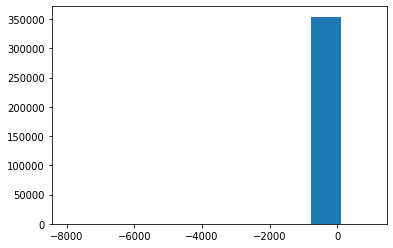

In [392]:
plt.hist(df['Age'])
plt.show()

Посмотрим на распределение. Странное.

In [393]:
df['Age'].value_counts(normalize=True)

 16      0.069110
 17      0.064134
 11      0.062385
 15      0.056786
 10      0.056157
           ...   
-1684    0.000003
-4484    0.000003
-884     0.000003
-5484    0.000003
 70      0.000003
Name: Age, Length: 151, dtype: float64

Можно увидеть, что некоторые автомобили имеют "отрицательный возраст". Это не имеет смысла.

In [394]:
len(df.query('Age < 0')) / len(df) * 100

4.100292071733946

4 % - довольно большое значение, но все же от него приемлемо избавиться.

In [395]:
df.query('Age < 0').head()

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen,Age
22,2016-03-23 14:52:51,2900,NaN,2018,manual,90,meriva,150000,5,petrol,opel,no,2016-03-23,0,49716,2016-03-31 01:16:33,-2
26,2016-03-10 19:38:18,5555,NaN,2017,manual,125,c4,125000,4,NaN,citroen,no,2016-03-10,0,31139,2016-03-16 09:16:46,-1
48,2016-03-25 14:40:12,7750,NaN,2017,manual,80,golf,100000,1,petrol,volkswagen,NaN,2016-03-25,0,48499,2016-03-31 21:47:44,-1
51,2016-03-07 18:57:08,2000,NaN,2017,manual,90,punto,150000,11,gasoline,fiat,yes,2016-03-07,0,66115,2016-03-07 18:57:08,-1
57,2016-03-10 20:53:19,2399,NaN,2018,manual,64,other,125000,3,NaN,seat,no,2016-03-10,0,33397,2016-03-25 10:17:37,-2


In [396]:
df = df.query('Age >= 0').reset_index(drop=True)

In [397]:
df['Age'].value_counts(normalize=True)

16     0.072064
17     0.066877
11     0.065052
15     0.059214
10     0.058558
         ...   
85     0.000003
328    0.000003
70     0.000003
67     0.000003
763    0.000003
Name: Age, Length: 110, dtype: float64

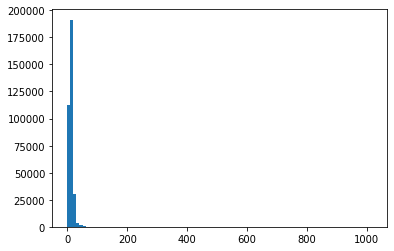

In [398]:
plt.hist(df['Age'], bins=100)
plt.show()

Отрицательных значений больше нет, но меются сильно положительные.

In [399]:
len(df.query('Age > 60')) / len(df) * 100

0.09563464622537407

От 0,1% избавиться легко и приятно.

In [400]:
df = df.query('Age < 60').reset_index(drop=True)

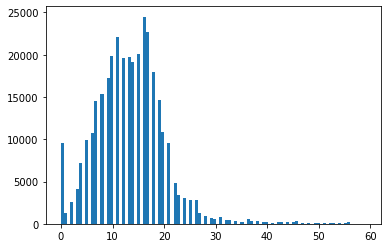

In [401]:
plt.hist(df['Age'], bins=100)
plt.show()

In [402]:
len(df.query('Price == 0')) / len(df) * 100

2.929454494039466

In [403]:
df = df.query('Price != 0').reset_index(drop=True)

<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

В данных остались машины только с адекватной ценой 👍
</div>

Пропуски в целевом признаке недопустимы.

(array([3.28834e+05, 4.15000e+02, 6.80000e+01, 6.60000e+01, 5.00000e+01,
        1.80000e+01, 7.00000e+00, 1.00000e+00, 3.00000e+00, 1.00000e+00,
        0.00000e+00, 4.00000e+00, 0.00000e+00, 3.00000e+00, 3.00000e+00,
        8.00000e+00, 1.00000e+00, 1.00000e+00, 8.00000e+00, 0.00000e+00,
        1.00000e+00, 2.00000e+00, 3.00000e+00, 0.00000e+00, 0.00000e+00,
        4.00000e+00, 4.00000e+00, 5.00000e+00, 2.00000e+00, 1.00000e+00,
        1.00000e+00, 5.00000e+00, 0.00000e+00, 0.00000e+00, 2.00000e+00,
        1.00000e+00, 0.00000e+00, 4.00000e+00, 0.00000e+00, 0.00000e+00,
        3.00000e+00, 0.00000e+00, 2.00000e+00, 1.00000e+00, 2.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 3.00000e+00, 1.00000e+00]),
 array([    0.,   400.,   800.,  1200.,  1600.,  2000.,  2400.,  2800.,
         3200.,  3600.,  4000.,  4400.,  4800.,  5200.,  5600.,  6000.,
         6400.,  6800.,  7200.,  7600.,  8000.,  8400.,  8800.,  9200.,
         9600., 10000., 10400., 10800., 11200., 1160

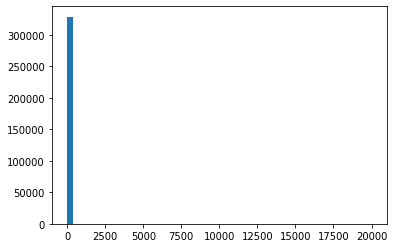

In [404]:
plt.hist(df['Power'], bins=50)

In [405]:
len(df.query('Power == 0')) / len(df) * 100

9.93785238728159

In [406]:
len(df.query('Power > 1000')) / len(df) * 100

0.07950524673937452

In [407]:
df = df.query('Power <= 1000').reset_index(drop=True)

<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

Мощность ограничили 👍
</div>

Удалили аномальные значения мощности.

In [408]:
df['RegistrationMonth'].value_counts(normalize=True)

3     0.099187
6     0.090286
0     0.089083
4     0.083927
5     0.083629
7     0.078181
10    0.075265
11    0.069759
12    0.069513
9     0.068793
1     0.066485
8     0.064836
2     0.061055
Name: RegistrationMonth, dtype: float64

Но ведь... нулевого месяца не существует

In [409]:
df['NumberOfPictures'].value_counts(normalize=True)

0    1.0
Name: NumberOfPictures, dtype: float64

Не информативно.

In [410]:
df = df.drop(columns=['RegistrationMonth', 'NumberOfPictures', 'RegistrationYear', 'LastSeen', 'DateCrawled', 'PostalCode', 'DateCreated'])

<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

Удалить неинформативные признаки - хорошее решение 👍
</div>

Можно принять тактическое решение избавться от ненужных столбцов.

In [411]:
missing_values_report = df.isna().sum().to_frame()
missing_values_report = missing_values_report.rename(columns = {0: 'missing_values'})
missing_values_report['% of total'] = (missing_values_report['missing_values'] / df.shape[0]).round(4) * 100
missing_values_report.sort_values(by = 'missing_values', ascending = False, inplace=True)
display(missing_values_report)

,missing_values,% of total
Repaired,59683,18.13
FuelType,24069,7.31
VehicleType,19880,6.04
Model,15518,4.71
Gearbox,15517,4.71
Price,0,0.00
Power,0,0.00
Kilometer,0,0.00
Brand,0,0.00
Age,0,0.00


In [412]:
display(df['Repaired'].value_counts(normalize=True, dropna=False))

no     0.718810
NaN    0.181255
yes    0.099934
Name: Repaired, dtype: float64

In [413]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 329276 entries, 0 to 329275
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Price        329276 non-null  int64 
 1   VehicleType  309396 non-null  object
 2   Gearbox      313759 non-null  object
 3   Power        329276 non-null  int64 
 4   Model        313758 non-null  object
 5   Kilometer    329276 non-null  int64 
 6   FuelType     305207 non-null  object
 7   Brand        329276 non-null  object
 8   Repaired     269593 non-null  object
 9   Age          329276 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 25.1+ MB


In [414]:
df.head()

,Price,VehicleType,Gearbox,Power,Model,Kilometer,FuelType,Brand,Repaired,Age
0,480,NaN,manual,0,golf,150000,petrol,volkswagen,NaN,23
1,18300,coupe,manual,190,NaN,125000,gasoline,audi,yes,5
2,9800,suv,auto,163,grand,125000,gasoline,jeep,NaN,12
3,1500,small,manual,75,golf,150000,petrol,volkswagen,no,15
4,3600,small,manual,69,fabia,90000,gasoline,skoda,no,8


<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

Для моделей, основанных на деревьях решений, порядковое кодирование отлично подойдет 👍
</div>

<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b>

Кодировать данные стоит после разбиения. Так у нас не будет утечки данных.

Подробнее об этом можно прочитать здесь https://datascience.stackexchange.com/questions/108663/why-label-encoding-before-split-is-data-leakage
  
Суть в том, что в предобработке данных мы не должны заглядывать в тестовую выборку. Когда кодировщик fit-ится на всей выборке, там ведь есть и тестовая выборка, поэтому это называют утечкой или подглядыванием. 

P.S. после прямого кодирования кол-во столбцов в выборках может отличаться. Тогда лишние признаки можно удалить
</div>

<div class="alert alert-block alert-success">
<b>V2 ✔️ Успешно исправлено</b>
</div>

Так как доля пропусков очень существенна, закодируем их как отдельное значение

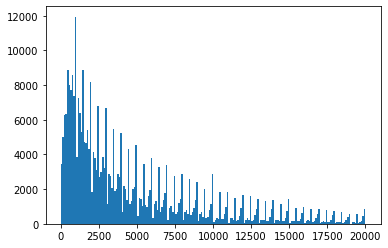

In [415]:
plt.hist(df['Price'], bins=200)
plt.show()

<AxesSubplot:>

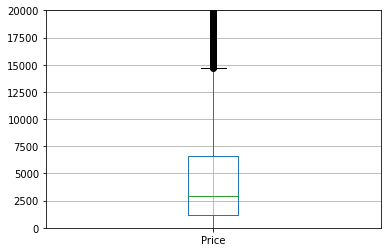

In [416]:
plt.ylim(0, 20000)
df.boxplot(column='Price')

С ценами все в целом нормально

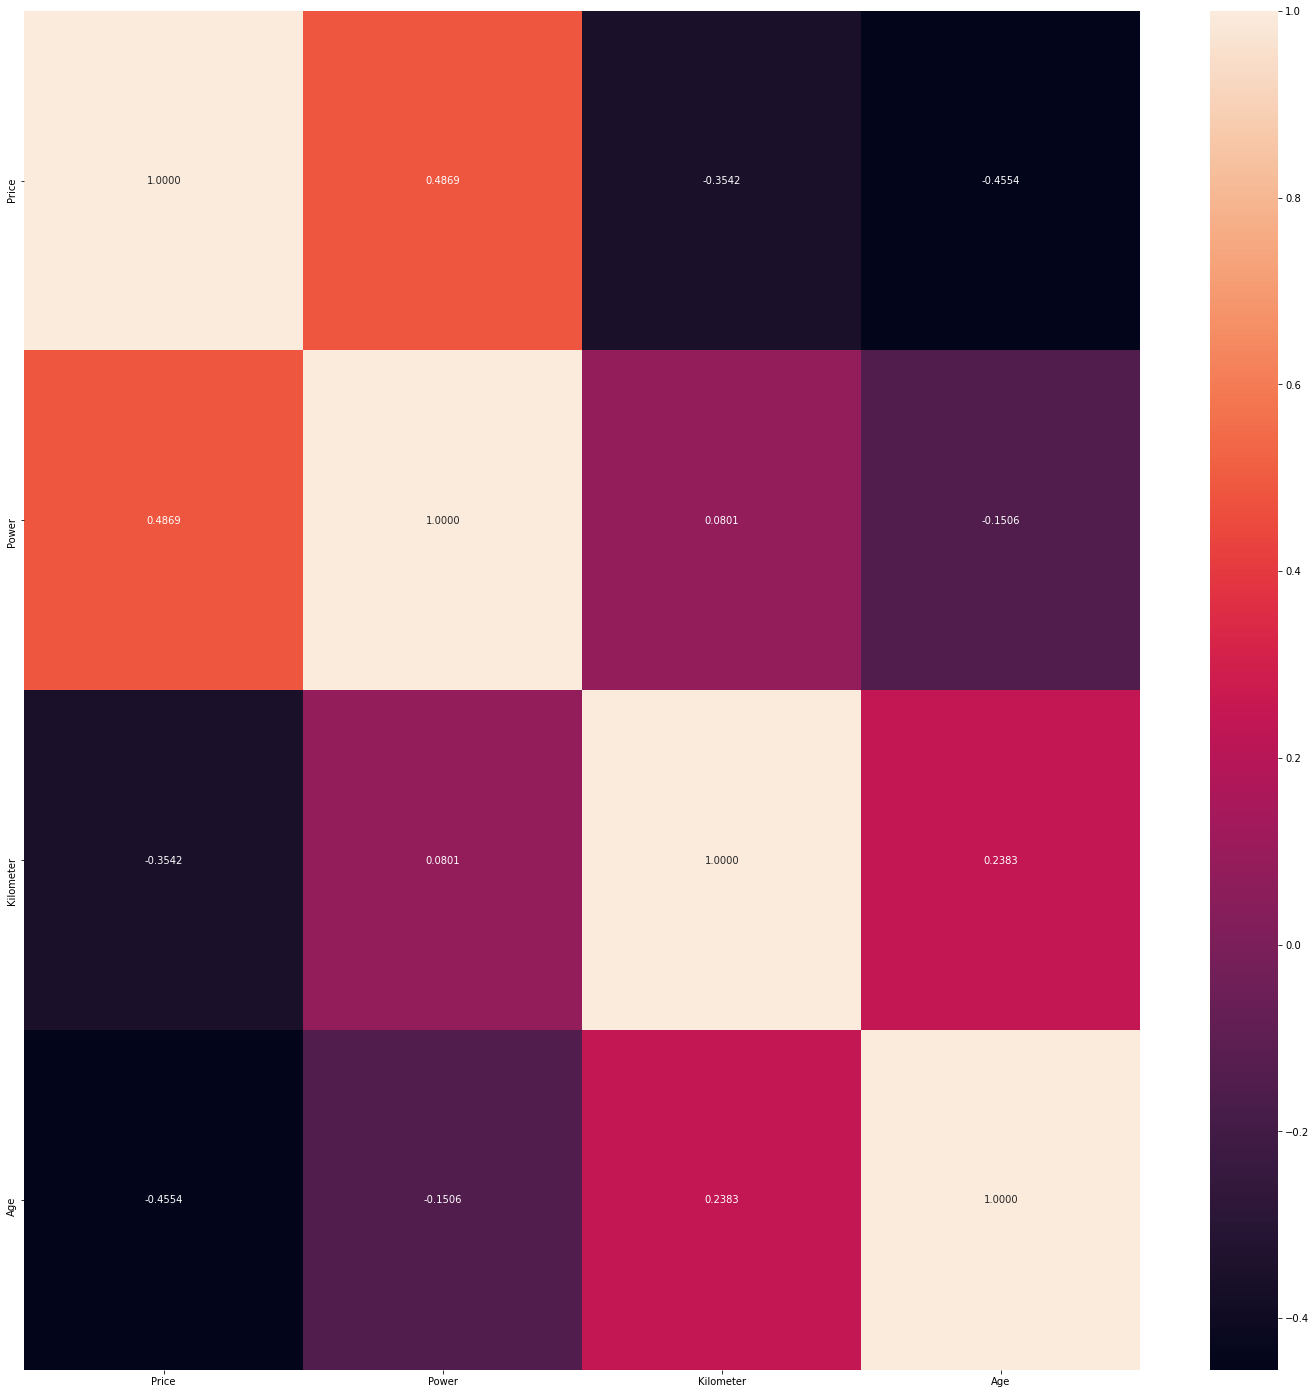

In [417]:
plt.figure(figsize=(25,25))
sns.heatmap(df.corr(), annot=True, fmt='.4f')
plt.show();

Посмотрим на корреляцию. Наибольшее влияние на цену имеют мощность, пробег, возраст

## Обучение моделей

In [418]:
features = df.drop(columns='Price')
target = df['Price']

In [419]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 329276 entries, 0 to 329275
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Price        329276 non-null  int64 
 1   VehicleType  309396 non-null  object
 2   Gearbox      313759 non-null  object
 3   Power        329276 non-null  int64 
 4   Model        313758 non-null  object
 5   Kilometer    329276 non-null  int64 
 6   FuelType     305207 non-null  object
 7   Brand        329276 non-null  object
 8   Repaired     269593 non-null  object
 9   Age          329276 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 25.1+ MB


<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b>

Масштабировать тоже стоит после разбиения)
</div>

<div class="alert alert-block alert-success">
<b>V2 ✔️ Успешно исправлено</b>
</div>

Стандартизируем изначально количественные признаки

In [420]:
features.head()

,VehicleType,Gearbox,Power,Model,Kilometer,FuelType,Brand,Repaired,Age
0,NaN,manual,0,golf,150000,petrol,volkswagen,NaN,23
1,coupe,manual,190,NaN,125000,gasoline,audi,yes,5
2,suv,auto,163,grand,125000,gasoline,jeep,NaN,12
3,small,manual,75,golf,150000,petrol,volkswagen,no,15
4,small,manual,69,fabia,90000,gasoline,skoda,no,8


In [421]:
features_tv, features_test, target_tv, target_test = train_test_split(features,
                                                                       target, test_size=0.2, random_state=12345)

In [422]:
numeric = ['Power', 'Kilometer', 'Age']
scaler = StandardScaler()
scaler.fit(features_test[numeric])
features_test[numeric] = scaler.transform(features_test[numeric])

/tmp/ipykernel_107/2691122957.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_test[numeric] = scaler.transform(features_test[numeric])
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


In [423]:
features_test_or = features_test
encoder = LabelEncoder()
cs = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'Brand', 'Repaired']
features_test.loc[:, cs] = features_test.loc[:, cs].astype(str).apply(encoder.fit_transform)

/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1787: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, val, pi)


In [424]:
features_ohe = pd.get_dummies(features, dummy_na=True, columns=cs)
scaler = StandardScaler()
scaler.fit(features_ohe[numeric])
features_ohe[numeric] = scaler.transform(features_ohe[numeric])
features_tv_ohe, features_test_ohe, target_tv_ohe, target_test_ohe = train_test_split(features_ohe,
                                                                       target, test_size=0.2, random_state=12345)
features_train_ohe, features_valid_ohe, target_train_ohe, target_valid_ohe = train_test_split(features_tv_ohe,
                                                                                              target_tv_ohe, test_size=0.25, 
                                                                                              random_state=12345)

In [425]:
features_train, features_valid, target_train, target_valid = train_test_split(features_tv, target_tv, test_size=0.25, random_state=12345) 

In [426]:
scaler = StandardScaler()
scaler.fit(features_train[numeric])
features_train[numeric] = scaler.transform(features_train[numeric])

/tmp/ipykernel_107/2977706183.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_train[numeric] = scaler.transform(features_train[numeric])
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


In [427]:
features_train_or = features_train
encoder = LabelEncoder()
cs = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'Brand', 'Repaired']
features_train.loc[:, cs] = features_train.loc[:, cs].astype(str).apply(encoder.fit_transform)

/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1787: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, val, pi)


In [428]:
scaler = StandardScaler()
scaler.fit(features_valid[numeric])
features_valid[numeric] = scaler.transform(features_valid[numeric])

/tmp/ipykernel_107/3762946794.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_valid[numeric] = scaler.transform(features_valid[numeric])
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


In [429]:
features_valid_or = features_valid
encoder = LabelEncoder()
cs = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'Brand', 'Repaired']
features_valid.loc[:, cs] = features_valid.loc[:, cs].astype(str).apply(encoder.fit_transform)

/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1787: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, val, pi)


In [430]:
print(len(features_valid_ohe), len(target_valid))

65855 65855


In [431]:
features_train_ohe.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 197565 entries, 148787 to 256930
Columns: 318 entries, Power to Repaired_nan
dtypes: float64(3), uint8(315)
memory usage: 65.4 MB


In [432]:
features_valid_ohe.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 65855 entries, 327222 to 243404
Columns: 318 entries, Power to Repaired_nan
dtypes: float64(3), uint8(315)
memory usage: 21.8 MB


<div class="alert alert-block alert-success">
<b>✔️ Успех:</b> 

Данные поделены верно, пропорции выбраны адекватные 👍
</div>

In [433]:
scorer = make_scorer(mean_squared_error)

In [434]:

#RandomForest_params_model = RandomForestRegressor(random_state=42)
#params = {'n_estimators': range(197, 200), 'max_depth': range(2, 3)}
#grid = GridSearchCV(RandomForest_params_model, params, cv=5, scoring=scorer)
#grid.fit(features_train, target_train)
#print(grid.best_params_)
RandomForest_model = RandomForestRegressor(random_state=42, max_depth=2, n_estimators=198)
RandomForest_model.fit(features_train, target_train)

RandomForest_predictions = RandomForest_model.predict(features_valid)
RandomForest_rmse_value = mean_squared_error(target_valid, RandomForest_predictions) ** 0.5
print(RandomForest_rmse_value)
print('actual time is')
#print(grid.cv_results_)

forest_fit_time = 0.2486493
forest_score_time = 0.00315184

3166.959436172435
actual time is


<div class="alert alert-block alert-success">
<b>✔️ Успех:</b> 

Модель обучена корректно 👍
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Совет:</b>

Из того же GridSearchCV мы можем получить время обучения и время предсказания)

В атрибуте `cv_results_` есть среднее время обучения и среднее время предсказания для всех комбинаций.
</div>

Модель случайного исследования интересна в данном исследовании как пример модели ансамбля

forest_time = 16 * 60 + 12

In [435]:
%%time
linear_model = LinearRegression()
linear_model.fit(features_train_ohe, target_train_ohe)

CPU times: user 12 s, sys: 5.2 s, total: 17.2 s
Wall time: 17.2 s


LinearRegression()

In [436]:
linear_fit_time = 15.7

In [437]:
%%time
linear_predictions = linear_model.predict(features_valid_ohe)

CPU times: user 30.7 ms, sys: 78.3 ms, total: 109 ms
Wall time: 82.1 ms


In [438]:
linear_predict_time = 80 / 1000

In [439]:
linear_model_rmse = mean_squared_error(target_valid_ohe, linear_predictions) ** 0.5
print(linear_model_rmse)

2682.494049331761


<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b>

Для линейных моделей лучше использовать прямое кодирование
</div>

<div class="alert alert-block alert-success">
<b>V2 ✔️ Успешно исправлено</b>
</div>

Модель линейной регрессии с решением данной задачи, однако, справляется лучше

In [440]:
linear_time = 70.9 / 1000

In [441]:
train_d = lightgbm.Dataset(features_train, label=target_train, categorical_feature = cs)
test_d = lightgbm.Dataset(features_valid, label=target_valid)
parameters = {'metric': 'rmse',  'is_unbalance': 'true', 'boosting': 
              'gbdt', 'num_leaves': 31, 'feature_fraction': 0.5, 
              'bagging_fraction': 0.5,  'bagging_freq': 20,  
              'learning_rate': 0.05}

In [442]:
%%time
LightGBM_model = lightgbm.train(parameters, train_set=train_d, valid_sets=test_d, num_boost_round=100)

/opt/conda/lib/python3.9/site-packages/lightgbm/basic.py:2065: UserWarning: Using categorical_feature in Dataset.
  _log_warning('Using categorical_feature in Dataset.')
/opt/conda/lib/python3.9/site-packages/lightgbm/basic.py:2068: UserWarning: categorical_feature in Dataset is overridden.
New categorical_feature is ['Brand', 'FuelType', 'Gearbox', 'Model', 'Repaired', 'VehicleType']
  _log_warning('categorical_feature in Dataset is overridden.\n'


[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.089192 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 644
[LightGBM] [Info] Number of data points in the train set: 197565, number of used features: 9
[LightGBM] [Info] Start training from score 4612.763268
[1]	valid_0's rmse: 4401.81


/opt/conda/lib/python3.9/site-packages/lightgbm/basic.py:1780: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning('Overriding the parameters from Reference Dataset.')
/opt/conda/lib/python3.9/site-packages/lightgbm/basic.py:1513: UserWarning: categorical_column in param dict is overridden.
  _log_warning(f'{cat_alias} in param dict is overridden.')


[2]	valid_0's rmse: 4246.09
[3]	valid_0's rmse: 4140.03
[4]	valid_0's rmse: 4085.5
[5]	valid_0's rmse: 3954.61
[6]	valid_0's rmse: 3883.85
[7]	valid_0's rmse: 3831.29
[8]	valid_0's rmse: 3713.23
[9]	valid_0's rmse: 3603.56
[10]	valid_0's rmse: 3494.73
[11]	valid_0's rmse: 3418.14
[12]	valid_0's rmse: 3323.83
[13]	valid_0's rmse: 3233.06
[14]	valid_0's rmse: 3162.4
[15]	valid_0's rmse: 3084.77
[16]	valid_0's rmse: 3024.84
[17]	valid_0's rmse: 2949.59
[18]	valid_0's rmse: 2896.95
[19]	valid_0's rmse: 2849.03
[20]	valid_0's rmse: 2814.34
[21]	valid_0's rmse: 2788.88
[22]	valid_0's rmse: 2773.57
[23]	valid_0's rmse: 2737.71
[24]	valid_0's rmse: 2710.52
[25]	valid_0's rmse: 2674.19
[26]	valid_0's rmse: 2661.95
[27]	valid_0's rmse: 2609.74
[28]	valid_0's rmse: 2587.33
[29]	valid_0's rmse: 2540.21
[30]	valid_0's rmse: 2522.2
[31]	valid_0's rmse: 2480.29
[32]	valid_0's rmse: 2467.98
[33]	valid_0's rmse: 2448.98
[34]	valid_0's rmse: 2413.19
[35]	valid_0's rmse: 2385.09
[36]	valid_0's rmse: 2354

In [443]:
light_train_time = 21

In [444]:
%%time
LightGBM_predictions = LightGBM_model.predict(features_valid)

CPU times: user 639 ms, sys: 0 ns, total: 639 ms
Wall time: 600 ms


In [445]:
light_predict_time = 612 / 1000

In [446]:
LightGBM_rmse_value = mean_squared_error(target_valid, LightGBM_predictions) ** 0.5
print(LightGBM_rmse_value)

1937.9276275711736


Неповторимый результат градиентного бустинга. И относительно недолго.

In [447]:
light_time = 57.1 

<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b>
    
Анализ моделей не должен включать тестовую выборку. Тестовая выборка используется в самом конце - в финальном тестировании лучшей модели. 

Если валидациционной выборки нет, то анализ моделей должен выглядеть так:

1. RMSE вычисляется с помощью кросс-валидации на тренировочной выборке
2. Время обучения = время model.fit(X_train, y_train)
3. Время предсказания = model.predict(X_train)
</div>

<div class="alert alert-block alert-success">
<b>V2 ✔️ Успешно исправлено</b>
</div>

## Анализ моделей

In [448]:
results = pd.DataFrame({'model':['RandomForest', 'LinearRegression', 'LightGBM'],
                       'fit time':[forest_fit_time, linear_fit_time, light_train_time],
                       'predict_time':[forest_score_time, linear_predict_time, light_predict_time],
                       'rmse':[RandomForest_rmse_value, linear_model_rmse, LightGBM_rmse_value]})
print(results)
                       

              model   fit time  predict_time         rmse
0      RandomForest   0.248649      0.003152  3166.959436
1  LinearRegression  15.700000      0.080000  2682.494049
2          LightGBM  21.000000      0.612000  1937.927628


<div class="alert alert-block alert-success">
<b>✔️ Успех:</b>

Молодец, что для сравнения моделей заносишь их в общий датафрейм 👍
</div>

<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b>

В сравнении нужно смотреть отдельно на время обучения и время предсказания для каждой модели.
</div>

<div class="alert alert-block alert-success">
<b>V2 ✔️ Успешно исправлено</b>
</div>

На реализацию модели случайного леса с подбором наилучших гиперпарамет ров уходит наибольшее количество времени, а средняя стандартная ошибка наибольшая.
Наименьшее количество времени уходит на создание модели линейной регерссии
Однако LightGBM, несущественно уступая во времени модели линейной регрессии, является оптималь ной в решении данно задачи.

# Тестирование лучшей модели

In [449]:
LightGBM_predictions = LightGBM_model.predict(features_test)
LightGBM_rmse_value = mean_squared_error(target_test, LightGBM_predictions) ** 0.5
print(LightGBM_rmse_value)

1947.6772458374292


Таким образом, проведя исследование трех моделей, модель градиентного бустинга может быть с уверенностью порекомендована для решения этой задачи. Показатель ее метрики намного превышает показатели других моделей, а время работы является приемлемым.

<div class="alert alert-block alert-danger">
<b>❌ Замечание:</b>

После анализа моделей нужно порекомендовать заказчику одну модель на основе его критериев и провести на ней финальное тестирование.

Рассчитай финальную метрику лучшей модели на тестовой выборке (до этого тестовая выборка нигде не должна использоваться). RMSE должно быть меньше 2500. Если метрика не дотягивает, попробуй исправить мои замечания, также можешь потюнить гиперпараметры (на этапе обучения моделей, не на тестовой выборке!)
</div>

<div class="alert alert-block alert-success">
<b>V2 ✔️ Успешно исправлено</b>
</div>

<div class="alert alert-block alert-info">
<b>Комментарий ревьюера:</b>

Чтобы все было ясно, напишу конкретный план (структуру) обучения и анализа моделей:

1. Обучение моделей. В обучении нужно рассмотреть хотя бы одну простую модель и один бустинг. Подбор гиперпараметров нужно провести хотя бы одной модели. Тут есть два варианта:
    - без валидационной выборки. Здесь нужно подбирать гиперпараметры с помощью кросс-валидации (GridSearchCV, RandomizedSearchCV или вручную (cross_val_score));
    - валидационная выборка есть. Здесь можно не использовать кросс-валидацию и подбирать гиперпараметры вручную.  
2. Анализ моделей. После нахождения лучших гиперпараметров стоит измерить время обучения, предсказания и RMSE. Тут тоже есть два варианта:
    - без валидационной выборки. RMSE на кросс-валидации. Время обучения = время model.fit(X_train). Время предсказания  = model.predict(X_train);
    - валидационная выборка есть. RMSE на validation. Время обучения = время model.fit(X_train). Время предсказания = время model.predict(X_valid).  
    
    После этого напиши вывод по анализу (можешь также результаты моделей занести в общую таблицу) и посоветуй заказчику одну модель на основе его критериев;
3. Тестирование. Рассчитай финальную метрику лучшей модели на тестовой выборке (до этого тестовая выборка нигде не должна использоваться!). RMSE должно быть меньше 2500. Если метрика не дотягивает, попробуй исправить мои замечания, также можешь потюнить гиперпараметры (на этапе обучения моделей, не на тестовой выборке!)
</div>

# <font color='orange'>Общее впечатление</font>
* Этот проект выполнен очень хорошо
* Видно, что приложено много усилий
* Молодец, что структурируешь ноутбук, приятно проверять такие работы
* У тебя чистый и лаконичный код
* Мне было интересно читать твои промежуточные выводы
* Твой уровень подачи материала находится на высоком уровне
* Исправь, пожалуйста, мои замечания. Затем отправляй на повторную проверку
* Жду новую версию проекта 👋

# <font color='orange'>2. Общее впечатление</font>
* Спасибо за быстрое внесение правок
* Теперь проект выглядит лучше )
* Критических замечаний нет
* Молодец, отличная работа!
* Надеюсь, ревью было полезным
* Удачи в дальнейшем обучении 👋

# <font color='orange'>Рекомендации 🔥</font>
* Доступное объяснение про работу градиентного бустинга https://www.youtube.com/watch?v=ZNJ3lKyI-EY&t=995s
* После просмотра видео можешь почитать статью про ансамбли и бустинги https://habr.com/ru/company/ods/blog/645887/
* Подбор гиперпараметров для CatBoost https://habr.com/ru/company/otus/blog/527554/
* Подбор гиперпараметров для LightGBM https://programmersought.com/article/40776531516/
* Разумные способы кодирования категориальных данных для машинного обучения https://machinelearningmastery.ru/smarter-ways-to-encode-categorical-data-for-machine-learning-part-1-of-3-6dca2f71b159/
* Статья про "непонятную" метрику ROC-AUC https://dyakonov.org/2017/07/28/auc-roc-площадь-под-кривой-ошибок/
* Хочешь подтянуть математику для DS?) https://academy.stepik.org/math-for-data-science
* Результы обучения моделей можно визуализировать 😎 https://www.datatechnotes.com/2019/08/elasticnet-regression-example-in-python.html
* В нашем деле нужно быть всегда в курсе всех новинок, новостей и тд, вот тут публикуют новости в области DS: https://www.infoq.com/data-analysis/news/
* Всем аналитикам данных рекомендую книгу Даниела Канемана "Думай медленно, решай быстро"